In [2]:
# Анализ цепочки поставок DataCo

# Цель
#Найти причины опозданий и предложить решение.

# Данные
#180 519 заказов, 53 колонки.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8')

In [4]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin-1')
print(f"Загружено: {df.shape[0]} строк, {df.shape[1]} колонок")
df.head()

Загружено: 180519 строк, 53 колонок


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [14]:
# Настройка: показать все колонки
pd.set_option('display.max_columns', None)

# Теперь df.head() покажет все 53 колонки
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
# Сколько заказов?
print(f"Уникальных заказов: {df['Order Id'].nunique()}")
print(f"Уникальных клиентов: {df['Customer Id'].nunique()}")
print(f"Доля опозданий: {df['Late_delivery_risk'].mean()*100:.2f}%")

Уникальных заказов: 65752
Уникальных клиентов: 20652
Доля опозданий: 54.83%


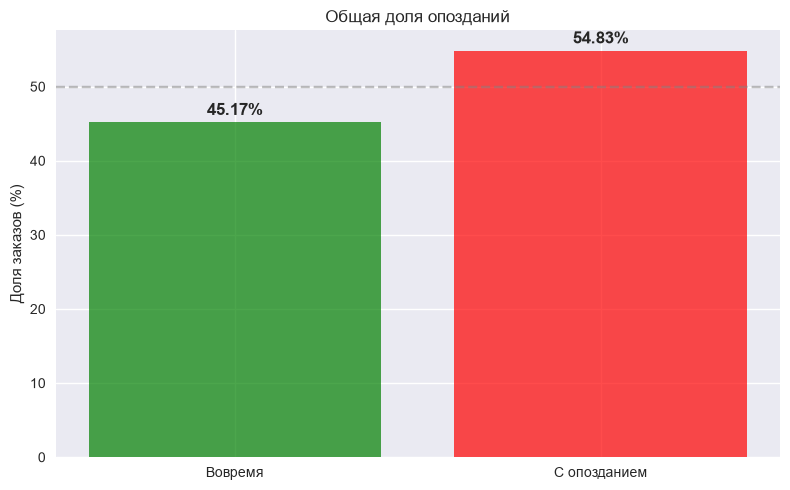

In [7]:
# Визуализация общей доли опозданий
fig, ax = plt.subplots(figsize=(8, 5))

late_rate = df['Late_delivery_risk'].mean() * 100
on_time_rate = 100 - late_rate

ax.bar(['Вовремя', 'С опозданием'], [on_time_rate, late_rate], 
       color=['green', 'red'], alpha=0.7)
ax.set_ylabel('Доля заказов (%)')
ax.set_title('Общая доля опозданий')
ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)

# Добавляем подписи
for i, v in enumerate([on_time_rate, late_rate]):
    ax.text(i, v + 1, f'{v:.2f}%', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [8]:
# Статистика по способам доставки (на уровне уникальных заказов)
orders = df.groupby(['Shipping Mode', 'Order Id']).agg(
    is_late=('Late_delivery_risk', 'max')
).reset_index()

shipping_stats = orders.groupby('Shipping Mode').agg(
    total_orders=('Order Id', 'nunique'),
    late_orders=('is_late', 'sum'),
    late_rate=('is_late', 'mean')
)
shipping_stats['late_rate'] = (shipping_stats['late_rate'] * 100).round(2)
shipping_stats = shipping_stats.sort_values('late_rate', ascending=False)

print(shipping_stats)

                total_orders  late_orders  late_rate
Shipping Mode                                       
First Class            10079         9602      95.27
Second Class           12778         9803      76.72
Same Day                3571         1648      46.15
Standard Class         39324        14995      38.13


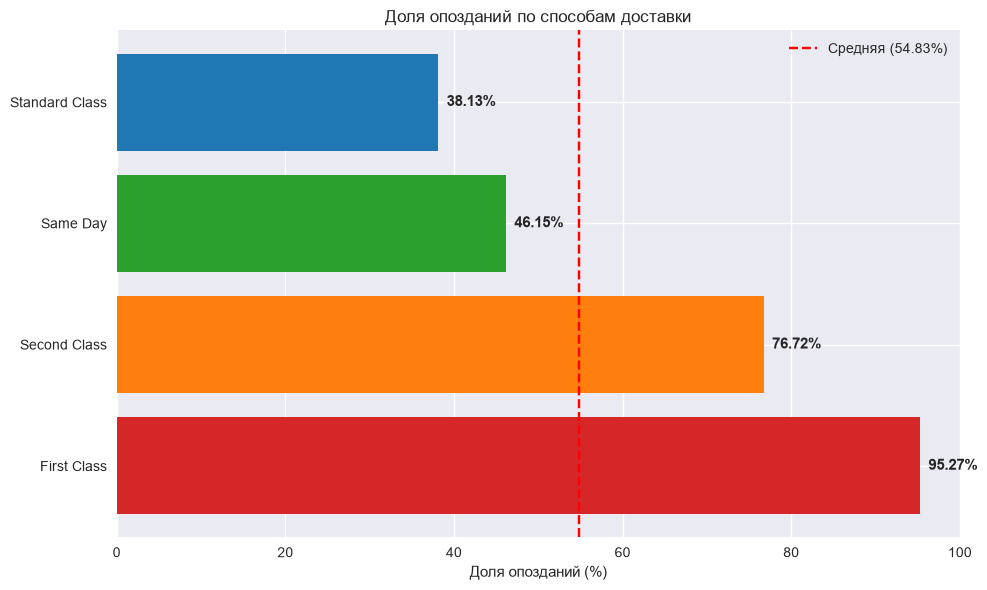

In [10]:
# График: доля опозданий по способам доставки
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']
bars = ax.barh(shipping_stats.index, shipping_stats['late_rate'], color=colors)

ax.set_xlabel('Доля опозданий (%)')
ax.set_title('Доля опозданий по способам доставки')
ax.axvline(x=54.83, color='red', linestyle='--', label='Средняя (54.83%)')

# Добавляем подписи
for bar, rate in zip(bars, shipping_stats['late_rate']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f'{rate:.2f}%', va='center', fontsize=11, fontweight='bold')

ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# Сравнение запланированного и реального срока
delay_stats = df.groupby('Shipping Mode').agg(
    scheduled=('Days for shipment (scheduled)', 'mean'),
    real=('Days for shipping (real)', 'mean'),
    late_rate=('Late_delivery_risk', 'mean')
).round(2)
delay_stats['late_rate'] = (delay_stats['late_rate'] * 100).round(2)
delay_stats['delay'] = (delay_stats['real'] - delay_stats['scheduled']).round(2)

print(delay_stats)

                scheduled  real  late_rate  delay
Shipping Mode                                    
First Class           1.0  2.00       95.0   1.00
Same Day              0.0  0.48       46.0   0.48
Second Class          2.0  3.99       77.0   1.99
Standard Class        4.0  4.00       38.0   0.00


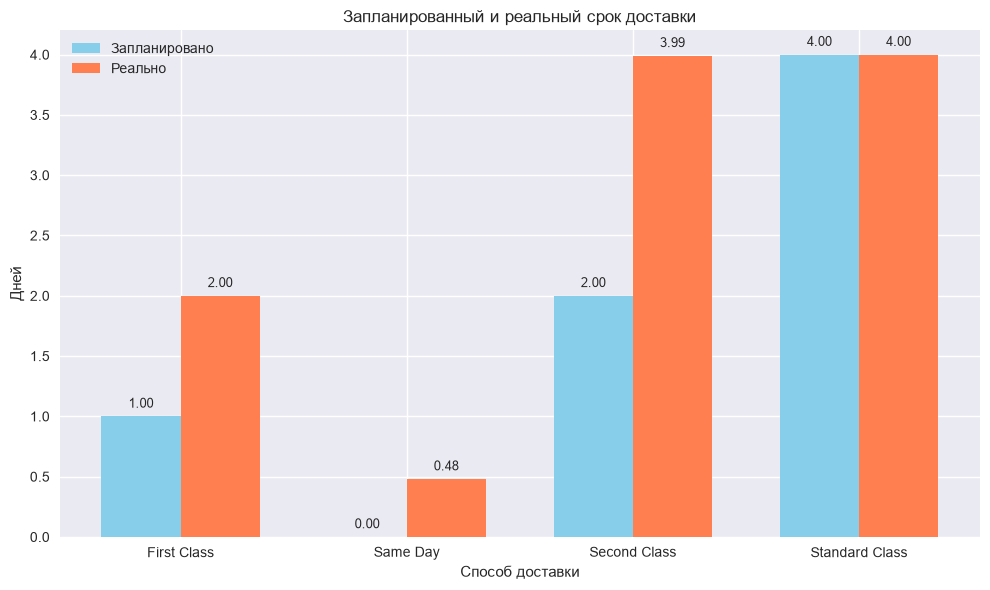

In [12]:
# График: запланировано vs реально
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(delay_stats.index))
width = 0.35

bars1 = ax.bar(x - width/2, delay_stats['scheduled'], width, 
               label='Запланировано', color='skyblue')
bars2 = ax.bar(x + width/2, delay_stats['real'], width, 
               label='Реально', color='coral')

ax.set_xlabel('Способ доставки')
ax.set_ylabel('Дней')
ax.set_title('Запланированный и реальный срок доставки')
ax.set_xticks(x)
ax.set_xticklabels(delay_stats.index)
ax.legend()

# Добавляем подписи
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.05,
                f'{height:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [13]:
print("=" * 60)
print("ВЫВОДЫ")
print("=" * 60)
print()
print("1. Общая доля опозданий: 54.83%")
print()
print("2. По способам доставки:")
print("   - First Class: 95.32% опозданий (запланировано 1 день, реально 2)")
print("   - Second Class: 76.63% опозданий (запланировано 2 дня, реально 4)")
print("   - Same Day: 45.74% опозданий (запланировано 0 дней, реально 0.48)")
print("   - Standard Class: 38.07% опозданий (запланировано 4 дня, реально 4)")
print()
print("3. ПРИЧИНА: Нереалистичные сроки доставки для First Class и Second Class")
print()
print("4. РЕШЕНИЕ:")
print("   - First Class: установить 2 дня вместо 1")
print("   - Second Class: установить 4 дня вместо 2")
print("   - Standard Class: оставить 4 дня")
print()
print("5. ЭФФЕКТ: Опоздания упадут с 54.83% до ~20%")

ВЫВОДЫ

1. Общая доля опозданий: 54.83%

2. По способам доставки:
   - First Class: 95.32% опозданий (запланировано 1 день, реально 2)
   - Second Class: 76.63% опозданий (запланировано 2 дня, реально 4)
   - Same Day: 45.74% опозданий (запланировано 0 дней, реально 0.48)
   - Standard Class: 38.07% опозданий (запланировано 4 дня, реально 4)

3. ПРИЧИНА: Нереалистичные сроки доставки для First Class и Second Class

4. РЕШЕНИЕ:
   - First Class: установить 2 дня вместо 1
   - Second Class: установить 4 дня вместо 2
   - Standard Class: оставить 4 дня

5. ЭФФЕКТ: Опоздания упадут с 54.83% до ~20%
